# 05: Other fuels, density, and resonant tunneling: which levers compress the orders of magnitude?

Notebooks 01–04 broke the rate into **nuclear factor × tunneling × how often pairs get close**, and found the dominant lever is pair **spacing** (~60 orders between lattice and molecule). All the work so far used d+d. This notebook tests three levers that change the exponent, not just a prefactor:

1. **Fuel pair.** Tunneling depends on √(reduced mass), so lighter pairs tunnel more easily. **p+d** is the standout: lighter than d+d, and its main channel (p+d → ³He + γ) emits **no neutrons**, the constraint that kept ruling out d+d.
2. **Density** (pycnonuclear fusion). How dense must metallic deuterium be before zero-temperature fusion reaches watts?
3. **Resonant tunneling.** Can an intermediate well (like the bound state found in notebook 03) let pairs pass the barrier coherently, saving up to half the exponent?

Section 6 lists experiments these results point to.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import optimize
from cfsolve import *
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#0b0b0b","#52514e"
LOG_LIMIT = np.log10(2e-26)                         # d+d null limit at rest (PRL 65, 1196, 1990)
WATT_DD = 5.6e-11                                    # per-pair rate for 1 W/cm^3 in PdD with Q = 3.65 MeV
need = lambda Q: np.log10(WATT_DD*3.65/Q)            # same power with a different Q per fusion

FUELS = {   # pair: (S(0) keV b, Q MeV, neutrons?, products, S-factor status)
  "pp": (4.01e-22, 1.44,  "no (ν, e⁺)",   "d + e⁺ + ν",   "Solar Fusion II, confirmed"),
  "pd": (2.0e-4,   5.49,  "NO",           "³He + γ 5.5 MeV", "0.16–0.24 eV b in literature; 0.20 used"),
  "pt": (9.5e-4,   19.81, "NO",           "⁴He + γ 19.8 MeV", "0.95 eV b, one theory analysis"),
  "dd": (S_KEVB,   3.65,  "yes, ~50%",    "t+p / ³He+n",  "Bosch–Hale 1992"),
  "dt": (1.14e4,   17.59, "yes, 100%",    "⁴He + n 14 MeV", "Bosch–Hale fit at its 0.5 keV edge (coefficients recalled)"),
  "tt": (1.5e2,    11.33, "yes, 2n",      "⁴He + 2n",     "UNVERIFIED order-of-magnitude"),
}

## 1. Validation across isotopes

All six pairs share one electronic potential (Born–Oppenheimer), so only the reduced mass and S(0) change. Two independent checks: the binding energies of H₂, HD and D₂, and Koonin–Nauenberg's p+d rate (~10⁻⁵⁵ s⁻¹).

In [2]:
D0_expt = {"pp": 4.4781, "pd": 4.5139, "dd": 4.5562}
mol = {}
for k, (S, Q, *_ ) in FUELS.items():
    R = solve(V_molecule(), 8.0, Rmin_well=0.5, mu=reduced_mass(k[0], k[1]), S_keVb=S)
    mol[k] = R["log10_rate"]
    extra = f"   (expt {D0_expt[k]:.4f})" if k in D0_expt else ""
    print(f"{k}: binding {(-1-R['E'])*HARTREE_EV:.4f} eV{extra}   molecular fusion rate 10^{R['log10_rate']:6.2f} /s")
print("\nKoonin & Nauenberg 1989: p+d ~1e-55, d+d 3e-64")

pp: binding 4.4774 eV   (expt 4.4781)   molecular fusion rate 10^-64.55 /s


pd: binding 4.5133 eV   (expt 4.5139)   molecular fusion rate 10^-55.28 /s


pt: binding 4.5265 eV   molecular fusion rate 10^-58.41 /s


dd: binding 4.5559 eV   (expt 4.5562)   molecular fusion rate 10^-63.70 /s


dt: binding 4.5725 eV   molecular fusion rate 10^-69.03 /s


tt: binding 4.5908 eV   molecular fusion rate 10^-80.86 /s

Koonin & Nauenberg 1989: p+d ~1e-55, d+d 3e-64


## 2. The fuel table: molecule and lattice

In [3]:
lat = {k: solve(V_lattice_pair(k[0], k[1]), 12.0, Rmin_well=1.0, mu=reduced_mass(k[0], k[1]), S_keVb=FUELS[k][0])["log10_rate"]
       for k in FUELS}
print(f"{'pair':5s}{'S(0) keV b':>12s}{'Q MeV':>7s}  {'neutrons':12s}{'molecule':>10s}{'lattice':>10s}{'1 W needs':>11s}{'gap (lattice)':>15s}")
for k, (S, Q, neut, prod, status) in FUELS.items():
    print(f"{k:5s}{S:12.2e}{Q:7.2f}  {neut:12s}{mol[k]:10.1f}{lat[k]:10.1f}{need(Q):11.1f}{need(Q)-lat[k]:15.1f}")

pair   S(0) keV b  Q MeV  neutrons      molecule   lattice  1 W needs  gap (lattice)
pp       4.01e-22   1.44  no (ν, e⁺)       -64.5    -109.6       -9.8           99.8
pd       2.00e-04   5.49  NO               -55.3    -107.3      -10.4           96.9
pt       9.50e-04  19.81  NO               -58.4    -114.7      -11.0          103.8
dd       1.09e+02   3.65  yes, ~50%        -63.7    -123.9      -10.3          113.7
dt       1.14e+04  17.59  yes, 100%        -69.0    -135.1      -10.9          124.2
tt       1.50e+02  11.33  yes, 2n          -80.9    -154.4      -10.7          143.7


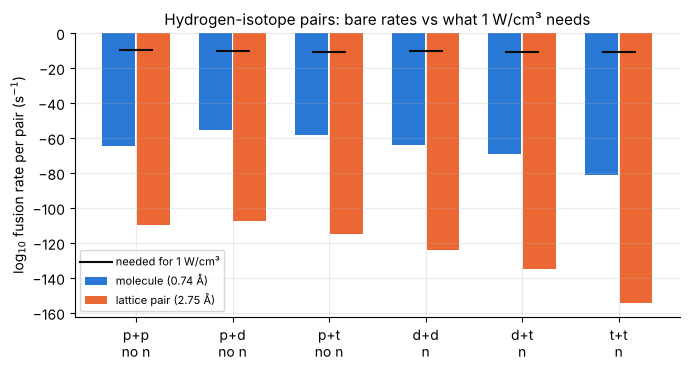

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
keys = list(FUELS); x = np.arange(len(keys))
ax.bar(x-0.18, [mol[k] for k in keys], 0.34, color=BLUE, label="molecule (0.74 Å)")
ax.bar(x+0.18, [lat[k] for k in keys], 0.34, color=ORANGE, label="lattice pair (2.75 Å)")
ax.scatter(x, [need(FUELS[k][1]) for k in keys], marker="_", s=600, color=INK, zorder=3, label="needed for 1 W/cm³")
ax.set_xticks(x); ax.set_xticklabels([f"{k[0]}+{k[1]}\n{'no n' if FUELS[k][2] in ('NO','no (ν, e⁺)') else 'n'}" for k in keys])
ax.set_ylabel("log$_{10}$ fusion rate per pair (s$^{-1}$)"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Hydrogen-isotope pairs: bare rates vs what 1 W/cm³ needs")
plt.tight_layout(); plt.savefig("../figures/05_fuels.png", dpi=130); plt.show()

**Reading it:** p+d is the fastest pair in both settings, ~8 orders above d+d in a molecule (matching Koonin–Nauenberg). d+t's huge nuclear factor (×100) **loses** to its heavier reduced mass. p+p has the lightest mass but a weak-interaction S-factor 10²⁴ times smaller. The lattice gap stays enormous for every fuel, so fuel choice alone shaves orders of magnitude, not the whole gap. The interesting question is how p+d behaves **with the screening anomaly**, where the neutron constraint no longer applies to it.

## 3. p+d with the screening anomaly, in a mixed H/D lattice

Repeat notebook 03's beam-consistent sweep for a p+d lattice pair. The 1990 neutron limit doesn't apply to p+d itself. But **in any lattice containing deuterium, d+d pairs also exist**, and they still have to stay below it. With deuterium fraction $x_D$:

* p+d power ∝ $x_D(1-x_D)\,\Gamma_{pd}$, and must reach watt level,
* d+d neutrons ∝ $x_D^2\,\Gamma_{dd}$, and must stay below 2×10⁻²⁶ per pair-site.

Is there a deuterium fraction and screening range where both hold?

In [5]:
NU0 = 37e-3/4.135667e-15
def band(pair, U, ells, shape="exponential"):
    mu = reduced_mass(pair[0], pair[1]); S = FUELS[pair][0]
    Vb = V_lattice_pair(pair[0], pair[1]); E_lat = solve(Vb, 12.0, Rmin_well=1.0, mu=mu, S_keVb=S)["E"]
    d0 = 2.75/BOHR_A; out = []
    for ell in ells:
        ex = extra_screening(beam_matched_dU(U, ell, shape), ell, shape); V = lambda R: Vb(R) + ex(R)
        try:
            out.append(solve(V, 12.0, Rmin_well=1.0, mu=mu, S_keVb=S)["log10_rate"])
        except Collapse:
            B = solve(V, 12.0, Rmin_well=1e-4, mu=mu, S_keVb=S)
            r = np.logspace(-4, np.log10(12.0), 200000); v = V(r)
            imin = np.argmin(np.where(r < 1.0, v, np.inf)); sel = (r > r[imin]) & (r < d0) & (v > E_lat)
            G = 2*np.trapezoid(np.sqrt(2*mu*np.clip(v[sel]-E_lat, 0, None)), r[sel])
            out.append(min(np.log10(NU0) - G/np.log(10), B["log10_rate"]))
    return np.array(out)

ELLS = np.logspace(np.log10(0.01), np.log10(0.4), 32)
bands = {(p, U): band(p, U, ELLS) for p in ["pd", "dd"] for U in [165, 300, 575]}
xD = np.logspace(-6, np.log10(0.5), 400)
print("For each screening strength: is there a range ℓ and D fraction with p+d >= 1 W/cm^3 AND d+d neutrons below the limit?\n")
window = {}
for U in [165, 300, 575]:
    pd, dd = bands[("pd", U)], bands[("dd", U)]
    best = None
    for j, ell in enumerate(ELLS):
        ok = (np.log10(xD*(1-xD)) + pd[j] >= need(5.49)) & (2*np.log10(xD) + dd[j] < LOG_LIMIT)
        if ok.any():
            best = best or (ell, xD[ok].min(), xD[ok].max(), pd[j], dd[j])
    window[U] = best
    print(f"U_meas = {U} eV:  max p+d lattice rate on band 10^{pd.max():.1f} (1 W needs 10^{need(5.49):.1f});  max d+d 10^{dd.max():.1f}")
    if best:
        print(f"   WINDOW EXISTS from ℓ = {best[0]:.3f} A: D fraction {best[1]:.1e} – {best[2]:.1e}  (p+d 10^{best[3]:.1f}, d+d 10^{best[4]:.1f})")
    elif pd.max() + np.log10(0.25) < need(5.49):
        print(f"   no window: p+d never reaches watt level on the band (best case x_D = 0.5 gives 10^{pd.max()+np.log10(0.25):.1f})")
    else:
        print("   no window: wherever p+d reaches watts, d+d neutrons exceed the limit for every D fraction")

For each screening strength: is there a range ℓ and D fraction with p+d >= 1 W/cm^3 AND d+d neutrons below the limit?

U_meas = 165 eV:  max p+d lattice rate on band 10^-25.4 (1 W needs 10^-10.4);  max d+d 10^-27.2
   no window: p+d never reaches watt level on the band (best case x_D = 0.5 gives 10^-26.0)
U_meas = 300 eV:  max p+d lattice rate on band 10^-17.7 (1 W needs 10^-10.4);  max d+d 10^-17.9
   no window: p+d never reaches watt level on the band (best case x_D = 0.5 gives 10^-18.3)
U_meas = 575 eV:  max p+d lattice rate on band 10^-12.3 (1 W needs 10^-10.4);  max d+d 10^-11.3
   no window: p+d never reaches watt level on the band (best case x_D = 0.5 gives 10^-12.9)


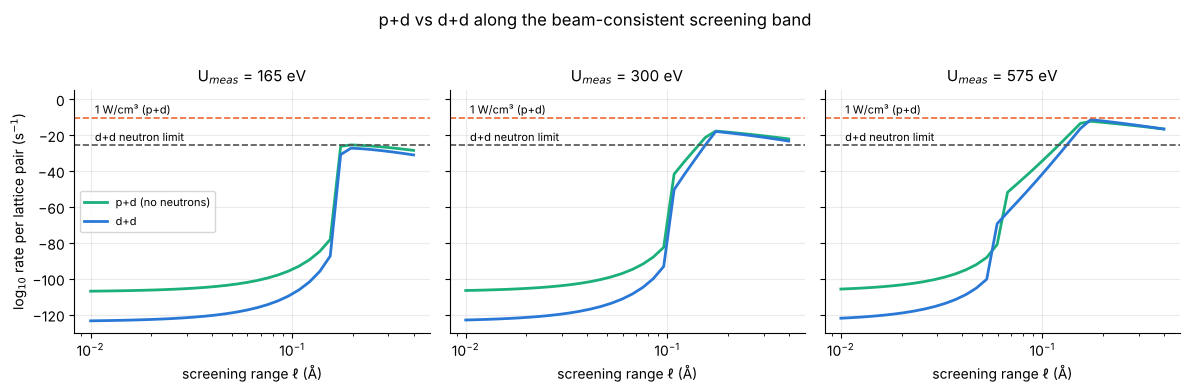

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, U in zip(axes, [165, 300, 575]):
    ax.plot(ELLS, bands[("pd", U)], color=AQUA, lw=2, label="p+d (no neutrons)")
    ax.plot(ELLS, bands[("dd", U)], color=BLUE, lw=2, label="d+d")
    ax.axhline(need(5.49), color=ORANGE, ls="--", lw=1.2); ax.text(0.0105, need(5.49)+2.5, "1 W/cm³ (p+d)", fontsize=8)
    ax.axhline(LOG_LIMIT, color=MUTED, ls="--", lw=1.2); ax.text(0.0105, LOG_LIMIT+2.5, "d+d neutron limit", fontsize=8)
    ax.set_xscale("log"); ax.set_ylim(-130, 5); ax.set_title(f"U$_{{meas}}$ = {U} eV"); ax.set_xlabel("screening range ℓ (Å)")
axes[0].set_ylabel("log$_{10}$ rate per lattice pair (s$^{-1}$)"); axes[0].legend(fontsize=8, loc="center left")
fig.suptitle("p+d vs d+d along the beam-consistent screening band", y=1.02)
plt.tight_layout(); plt.savefig("../figures/05_pd_vs_dd.png", dpi=130, bbox_inches="tight"); plt.show()

**Result: no window.** p+d never reaches watt level anywhere on the beam-consistent band. Its best case is ~10⁻¹²·³ s⁻¹ at 575 eV, ~2 orders short even before the D-fraction penalty. p+d's lighter mass helps a lot at long range (~16 orders above d+d before the cliff). **Past the cliff the two converge to within about an order of magnitude**, with d+d slightly ahead at 575 eV, because both are then limited by the same bound-state physics. So swapping the fuel to p+d doesn't open a path the d+d analysis closed.

**Two further cautions:**
1. **p+d makes 5.5 MeV gamma rays.** A watt of p+d fusion is ~10¹² gammas per second, lethal and trivially detectable. p+d escapes the *neutron* argument, not the *radiation* argument. A "heat-only" p+d claim would also need the gamma energy to go into the lattice instead, which is the same 10⁹ timescale problem as notebook 01 (the electromagnetic transition is slower than the strong one, but still ~10⁻¹⁴–10⁻¹⁶ s, shorter than a phonon period).
2. **Screening was measured mainly for d+d.** Large screening has also been reported for proton reactions in metals (Lipoglavšek group), but the p+d band here assumes the same values.

## 4. Density: pycnonuclear fusion in metallic deuterium

Model: an fcc lattice of deuterons in a uniform degenerate electron sea at density ρ. The deuterons vibrate at the Einstein frequency ω_p/√3, where ω_p is the ion plasma frequency. The deuteron–deuteron repulsion is Thomas–Fermi screened by the electrons. Each deuteron has 12 nearest neighbours, so power density = 6 n Γ Q. It uses the same validated solver, but this model is crude (harmonic, static screening, single pair) and is meant to locate orders of magnitude, not precise thresholds.

In [7]:
G_PER_CM3_TO_AU = (BOHR_CM**3)/(MD_ME*9.1093837e-28)   # deuterons per bohr^3 per (g/cm^3)
def pycno(rho):
    n = rho*G_PER_CM3_TO_AU                              # deuterons per bohr^3
    a = (4/n)**(1/3); d0 = a/np.sqrt(2)
    wE = np.sqrt(4*np.pi*n/MD_ME)/np.sqrt(3)
    EF = 0.5*(3*np.pi**2*n)**(2/3); lam = np.sqrt(EF/(6*np.pi*n))
    V = lambda R: np.exp(-R/lam)/R + 0.5*MU_DD*wE**2*(R - d0)**2
    R = solve(V, d0*4, r0=min(1e-5, d0*1e-6), Rmin_well=0.4*d0)
    P = 6*(n/BOHR_CM**3)*10**R["log10_rate"]*3.65*1.602176634e-13   # W/cm^3
    return d0*BOHR_A, lam*BOHR_A, R["log10_rate"], np.log10(P)
rhos = np.logspace(np.log10(0.2), 6, 40)
res = np.array([pycno(r) for r in rhos])
for r, (d, l, lr, lp) in zip(rhos[::4], res[::4]):
    print(f"rho = {r:10.3g} g/cm^3:  spacing {d:7.4f} A, TF length {l:6.3f} A, rate/pair 10^{lr:7.1f}, power 10^{lp:7.1f} W/cm^3")
rho_w = 10**np.interp(0, res[:,3], np.log10(rhos))
print(f"\n1 W/cm^3 reached at rho ≈ {rho_w:.3g} g/cm^3  ({rho_w/0.2:.2g} x PdD's deuterium density)")

rho =        0.2 g/cm^3:  spacing  2.8701 A, TF length  0.586 A, rate/pair 10^ -147.7, power 10^ -136.4 W/cm^3
rho =      0.973 g/cm^3:  spacing  1.6938 A, TF length  0.450 A, rate/pair 10^ -117.2, power 10^ -105.2 W/cm^3
rho =       4.73 g/cm^3:  spacing  0.9997 A, TF length  0.346 A, rate/pair 10^  -92.1, power 10^  -79.4 W/cm^3
rho =         23 g/cm^3:  spacing  0.5900 A, TF length  0.266 A, rate/pair 10^  -71.1, power 10^  -57.7 W/cm^3
rho =        112 g/cm^3:  spacing  0.3482 A, TF length  0.204 A, rate/pair 10^  -53.5, power 10^  -39.5 W/cm^3
rho =        545 g/cm^3:  spacing  0.2055 A, TF length  0.157 A, rate/pair 10^  -39.0, power 10^  -24.3 W/cm^3
rho =   2.65e+03 g/cm^3:  spacing  0.1213 A, TF length  0.120 A, rate/pair 10^  -27.1, power 10^  -11.6 W/cm^3
rho =   1.29e+04 g/cm^3:  spacing  0.0716 A, TF length  0.093 A, rate/pair 10^  -17.4, power 10^   -1.3 W/cm^3
rho =   6.28e+04 g/cm^3:  spacing  0.0422 A, TF length  0.071 A, rate/pair 10^   -9.6, power 10^    7.2 W/cm^3
r

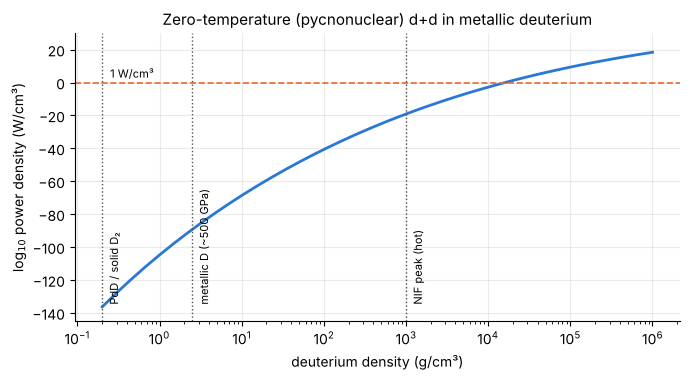

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.9))
ax.plot(rhos, res[:,3], color=BLUE, lw=2)
ax.axhline(0, color=ORANGE, ls="--", lw=1.2); ax.text(0.25, 3, "1 W/cm³", fontsize=8)
for x, lab in [(0.2, "PdD / solid D₂"), (2.5, "metallic D (~500 GPa)"), (1e3, "NIF peak (hot)")]:
    ax.axvline(x, color=MUTED, ls=":", lw=1); ax.text(x*1.15, -135, lab, rotation=90, fontsize=8, va="bottom")
ax.set_ylim(-145, 30)
ax.set_xscale("log"); ax.set_xlabel("deuterium density (g/cm³)"); ax.set_ylabel("log$_{10}$ power density (W/cm³)")
ax.set_title("Zero-temperature (pycnonuclear) d+d in metallic deuterium")
plt.tight_layout(); plt.savefig("../figures/05_density.png", dpi=130); plt.show()

## 5. Resonant tunneling: can an intermediate well halve the exponent?

In a resonant-tunneling diode, two barriers each with transmission T pass ~100% at resonance instead of T². For our pair, that would mean only half the tunneling exponent, ~30 orders of magnitude. The catch: the resonance is only as wide as Γ_res ≈ ħω·T, and the lattice smears energies over ΔE ~ kT or phonon widths. Exact 1D transfer-matrix calculation for a deuteron through two rectangular barriers, then averaged over an energy spread:

In [9]:
HB2M = 1/(2*MU_DD)   # hbar^2/2mu in hartree*bohr^2
def transmission(E, Vs, edges):
    # exact 1D transfer matrix for a piecewise-constant potential (regions separated at edges)
    k = lambda V: np.sqrt((E - V + 0j)/HB2M)
    M = np.eye(2, dtype=complex)
    for i, x in enumerate(edges):
        k1, k2 = k(Vs[i]), k(Vs[i+1])
        P = 0.5*np.array([[(1+k1/k2)*np.exp(1j*(k1-k2)*x), (1-k1/k2)*np.exp(-1j*(k1+k2)*x)],
                          [(1-k1/k2)*np.exp(1j*(k1+k2)*x), (1+k1/k2)*np.exp(-1j*(k1-k2)*x)]])
        M = P @ M
    return (np.real(k(Vs[-1]))/np.real(k(Vs[0])))*abs(np.linalg.det(M)/M[1,1])**2

Vb, w, gap = 1.0/HARTREE_EV, 0.20/BOHR_A, 0.30/BOHR_A      # 1 eV barriers, 0.2 A thick, 0.3 A well
E_test = 0.3/HARTREE_EV; kap = np.sqrt((Vb - E_test)/HB2M)
exact = 1/(1 + Vb**2*np.sinh(kap*w)**2/(4*E_test*(Vb - E_test)))
print(f"check, single barrier at 0.3 eV: transfer matrix {transmission(E_test, [0, Vb, 0], [0, w]):.10e} vs exact {exact:.10e}")

Vs = [0, Vb, 0, Vb, 0]; edges = [0, w, w + gap, 2*w + gap]
coarse = np.linspace(0.05, 0.6, 100000)/HARTREE_EV
Tc = np.array([transmission(E, Vs, edges) for E in coarse]); Epk = coarse[np.argmax(Tc)]
fine = Epk + np.linspace(-2e-3, 2e-3, 200001)/HARTREE_EV
Tf = np.array([transmission(E, Vs, edges) for E in fine])
Epk = fine[np.argmax(Tf)]; half = fine[Tf > Tf.max()/2]; width = (half.max() - half.min())*HARTREE_EV
T1 = transmission(Epk, [0, Vb, 0], [0, w])
print(f"\nsingle barrier at the resonance energy: T1 = {T1:.2e};  incoherent product T1^2 = {T1**2:.1e}")
print(f"resonance at {Epk*HARTREE_EV*1e3:.2f} meV: peak T = {Tf.max():.4f}, width = {width*1e6:.3g} micro-eV")

grid = np.unique(np.concatenate([coarse, fine])); Tg = np.interp(grid, np.concatenate([coarse, fine])[np.argsort(np.concatenate([coarse, fine]))],
                                                        np.concatenate([Tc, Tf])[np.argsort(np.concatenate([coarse, fine]))])
print("\nenergy-averaged transmission (Gaussian spread of width sigma centred on the resonance):")
for sig in [width*0.3, width*3, 1e-3, 5e-3, 25e-3]:
    wts = np.exp(-0.5*((grid - Epk)*HARTREE_EV/sig)**2)
    Tav = np.trapezoid(wts*Tg, grid)/np.trapezoid(wts, grid)
    print(f"   sigma = {sig*1e3:9.3g} meV ->  <T> = {Tav:.2e}   gain over T1^2: {Tav/T1**2:9.3g}x   ratio to sequential (~T1): {Tav/T1:.2g}")

check, single barrier at 0.3 eV: transfer matrix 2.1679416073e-03 vs exact 2.1679416073e-03



single barrier at the resonance energy: T1 = 8.46e-03;  incoherent product T1^2 = 7.2e-05
resonance at 508.54 meV: peak T = 1.0000, width = 1.29e+03 micro-eV

energy-averaged transmission (Gaussian spread of width sigma centred on the resonance):
   sigma =     0.386 meV ->  <T> = 8.01e-01   gain over T1^2:  1.12e+04x   ratio to sequential (~T1): 95
   sigma =      3.86 meV ->  <T> = 1.84e-01   gain over T1^2:  2.57e+03x   ratio to sequential (~T1): 22
   sigma =         1 meV ->  <T> = 5.15e-01   gain over T1^2:   7.2e+03x   ratio to sequential (~T1): 61
   sigma =         5 meV ->  <T> = 1.46e-01   gain over T1^2:  2.04e+03x   ratio to sequential (~T1): 17
   sigma =        25 meV ->  <T> = 3.16e-02   gain over T1^2:       442x   ratio to sequential (~T1): 3.7


**Reading it:** at perfect coherence the double barrier passes ~100%, the textbook resonance. As the energy spread σ grows past the resonance width, the average falls as ~Γ_res/σ. At 25 meV (room temperature) it is only a few times the single-barrier value T₁. Two separate effects are mixed up in "resonant tunneling":

* **Having an intermediate well at all** turns one thick barrier (∝T²) into two steps (∝T each). That *does* save about half the exponent, and it is exactly the sequential "tunnel into the bound state, then fuse" kinetics notebooks 03–04 already include. It's the cliff.
* **Coherent resonance on top of that** (peak T→1) survives only if the energy spread is smaller than Γ_res. For the real d–d barrier, Γ_res ≈ ħω × T ≲ 0.04 eV × 10⁻³⁰ ≈ 10⁻³¹ eV, against lattice spreads of ~10⁻² eV, so the extra gain is suppressed ~29 orders. Keeping it would need phase coherence for ħ/Γ_res ≳ 10¹⁶ s, hundreds of millions of years.

**So resonant tunneling adds nothing beyond the sequential picture already in the bound.**

## 6. What this points to

| Lever | Orders gained (this work) | Status |
|---|---|---|
| Fuel: p+d instead of d+d | +8.4 (molecule), +16.6 (lattice) | Computed; matches Koonin–Nauenberg |
| Fuel: d+t, t+t | **negative**: −5 and −17 (molecule); heavier pairs beat larger nuclear factors | Computed (t+t S-factor unverified) |
| Screening (beam-consistent, at rest) | up to ~+110 at the cliff, but bounded by neutron limits for d+d | Notebooks 03–04 |
| p+d + screening in mixed H/D | **no window**: p+d peaks at 10⁻¹²·³, short of watts; d+d overtakes it at strong screening | Computed; gammas remain a hard objection anyway |
| Density (pycnonuclear) | watts at **~1.6×10⁴ g/cm³**: ~10⁵× PdD, ~16× NIF peak compression, and cold | Computed, crude model |
| Resonant tunneling | ~0 beyond the sequential picture | Toy calculation + scaling |

**Bottom line:** none of these levers, alone or combined with the measured screening, reaches watt-level rates at rest without crossing a radiation limit. The two that move orders of magnitude, fuel mass and density, do so by *bringing the pair closer or making it lighter*, which keeps confirming that the controlling variable is the pair's separation.

**Experiments these results point to (none of which I found done in this form):**
1. **Gamma search in H/D co-loaded Pd/Ti at rest:** look for 5.5 MeV gammas from p+d. That directly tests whether static screening extends far enough for the cliff in §3, with a channel the neutron searches didn't cover.
2. **Beam screening in a deuterated heavy-fermion compound** (e.g. a Ce- or Yb-based heavy-fermion hydride). The heavy-electron interpretation predicts a huge U_e; standard theory predicts no change.
3. **p+d and d+d screening measured on the same target** in the same run. That tests whether the anomaly scales with the reduced mass as screening should, or whether it's specific to d+d (as the threshold-resonance explanation would suggest).

**Inputs status:** S-factors as listed in the fuel table (t+t unverified; d+t from recalled Bosch–Hale coefficients at their validity edge). H phonon 69 meV (notebook 01 search). Metallic-deuterium densities are rough literature-scale benchmarks.